# JEDI Job Annotation Dataset: Bias, Coverage, and Semi-Supervised Readiness Audit

**Project:** JEDI - Job Evaluation & Delivery Intelligence  
**Notebook goal:** inspect the first fully annotated job-screening dataset before using it for semi-supervised learning.

This notebook does not train the production model yet. Its purpose is to answer whether the current labels are balanced, representative, and trustworthy enough to become a seed set for model training or pseudo-labeling.

Main checks:
- target/class balance for `applied`
- source, company, role, seniority, location, work-mode, and employment-type coverage
- missingness and noisy fields
- score distributions and score/label alignment
- sparse strata and overrepresented strata
- practical sampling and weighting recommendations for the next annotation round

In [1]:
from pathlib import Path
import re
import math
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 80)
pd.set_option("display.max_colwidth", 140)

DATA_PATH = Path("jedi-annotated-2026-06-27_completed.csv")
if not DATA_PATH.exists():
    candidates = sorted(Path(".").glob("*annotated*.csv"))
    if candidates:
        DATA_PATH = candidates[-1]

DATA_PATH

PosixPath('jedi-annotated-2026-06-27_completed.csv')

In [2]:
df_raw = pd.read_csv(DATA_PATH)
df = df_raw.copy()

print(f"Loaded: {DATA_PATH}")
print(f"Rows: {df.shape[0]:,} | Columns: {df.shape[1]:,}")
display(df.head(3))
display(pd.DataFrame({"column": df.columns, "dtype": [df[c].dtype for c in df.columns]}))

Loaded: jedi-annotated-2026-06-27_completed.csv
Rows: 250 | Columns: 31


,row_id,source_platform,source_type,scraped_at,can_apply_now,company_name,company_match_score,role_title,role_title_preference_score,role_family,role_family_preference_score,seniority,seniority_profile_fit_score,location,location_profile_fit_score,work_mode,work_mode_fit_score,employment_type,experience_min_years,experience_max_years,experience_profile_fit_score,skills_or_requirements,skills_profile_fit_score,salary_min,salary_max,salary_profile_fit_score,freshness,overall_preference_score,preference_reason,applied,apply_url
0,1,Greenhouse,deterministic_scrape_candidate,2026-06-27,Yes,Nirmata,4,"Software Engineer Intern, India",5,Backend / Cloud,4,intern,5,"Bangalore, Hybrid",4,Hybrid,5,internship,0.0,1.0,5.0,Go; Java; microservices; Kubernetes; Prometheus; TimeScale; reliability; automation,2,1200000,1200000,5,Not visible,3,"Intern role is fine, everything is good but the requirements state Kubernetes, observability tools, promethus and Go which dont match wi...",no,https://job-boards.greenhouse.io/nirmata/jobs/5040355008
1,2,Greenhouse,deterministic_scrape_candidate,2026-06-27,Yes,CloudSEK,5,SDE - Backend - Intern,5,Backend,5,intern,5,"Bengaluru, Karnataka, India",4,Hybrid,5,internship,0.0,1.0,5.0,Backend engineering; cybersecurity product; APIs; databases likely,4,800000,900000,4,Not visible,4,"Backend intern in Bengaluru; very relevant for fresher profile, salary is a little less and location bengaluru",yes,https://job-boards.greenhouse.io/cloudsek/jobs/5766402004
2,3,Greenhouse,deterministic_scrape_candidate,2026-06-27,Yes,Anaplan,5,Associate Software Engineer,5,Backend / Fullstack,5,entry_level,5,"Gurugram, India",5,unknown,5,full_time,0.0,2.0,5.0,Software engineering; AI-infused platform; SaaS; cloud; planning systems,5,500000,700000,2,Not visible,3,Associate level in Gurgaon; high-quality company and location fitbut salary is quite less and the bad factor,yes,https://job-boards.greenhouse.io/anaplan/jobs/8511489002


,column,dtype
0,row_id,int64
1,source_platform,object
2,source_type,object
3,scraped_at,object
4,can_apply_now,object
5,company_name,object
6,company_match_score,int64
7,role_title,object
8,role_title_preference_score,int64
9,role_family,object


## 1. Basic Cleaning for Audit

The audit keeps the source data intact but creates normalized helper columns for analysis. This prevents misleading charts caused by inconsistent casing, spacing, or yes/no label variants.

In [3]:
def clean_text_value(value):
    if pd.isna(value):
        return np.nan
    text = str(value).strip()
    return np.nan if text == "" else text

def normalize_category(value):
    value = clean_text_value(value)
    if pd.isna(value):
        return "unknown"
    return re.sub(r"\s+", " ", str(value).strip()).lower()

def to_numeric(series):
    return pd.to_numeric(series, errors="coerce")

for col in df.columns:
    if df[col].dtype == "object":
        df[col] = df[col].map(clean_text_value)

score_cols = [c for c in df.columns if c.endswith("_score")]
year_cols = ["experience_min_years", "experience_max_years", "salary_min", "salary_max"]
for col in score_cols + [c for c in year_cols if c in df.columns]:
    df[col] = to_numeric(df[col])

if "applied" in df.columns:
    df["applied_clean"] = df["applied"].map(normalize_category)
    df["applied_binary"] = df["applied_clean"].map({"yes": 1, "y": 1, "true": 1, "1": 1, "no": 0, "n": 0, "false": 0, "0": 0})
else:
    raise ValueError("Expected an `applied` column as the target label.")

categorical_cols = [
    "source_platform", "source_type", "company_name", "role_family", "seniority",
    "location", "work_mode", "employment_type", "can_apply_now", "freshness"
]
for col in categorical_cols:
    if col in df.columns:
        df[f"{col}_clean"] = df[col].map(normalize_category)

df[["applied", "applied_clean", "applied_binary"]].head()

,applied,applied_clean,applied_binary
0,no,no,0.0
1,yes,yes,1.0
2,yes,yes,1.0
3,no,no,0.0
4,yes,yes,1.0


## 2. Target Class Balance

`applied` is the first practical predictor label. A heavily skewed target will make a first classifier appear accurate while learning a shallow majority-class rule.

,applied,count,share
0,no,126,0.504
1,active listing / apply visible or direct apply page found,100,0.400
2,yes,24,0.096


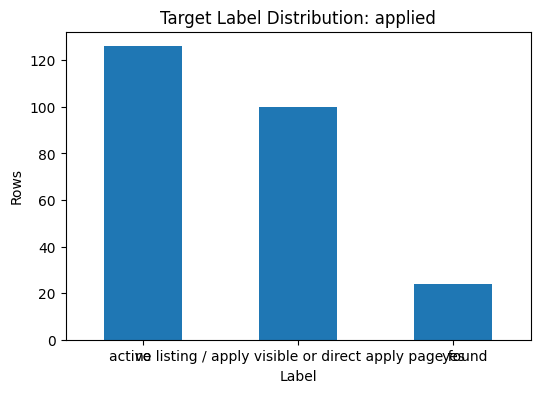

In [4]:
target_counts = df["applied_clean"].value_counts(dropna=False).rename_axis("applied").reset_index(name="count")
target_counts["share"] = target_counts["count"] / len(df)
display(target_counts)

ax = target_counts.plot.bar(x="applied", y="count", legend=False, figsize=(6, 4), color="#1f77b4")
ax.set_title("Target Label Distribution: applied")
ax.set_xlabel("Label")
ax.set_ylabel("Rows")
plt.xticks(rotation=0)
plt.show()

if df["applied_binary"].notna().all():
    pos_rate = df["applied_binary"].mean()
    print(f"Positive rate: {pos_rate:.1%}")
    if pos_rate < 0.25 or pos_rate > 0.75:
        print("Risk: target is materially imbalanced. Use stratified sampling, class weights, and balanced validation metrics.")
    else:
        print("Target balance is workable for a first seed model, but still use stratified validation.")

## 3. Missingness and Field Quality

Semi-supervised learning is sensitive to missing or systematically unavailable fields. If one source omits salary or freshness more often than another, the model may learn source artifacts instead of real job quality.

,column,missing_rate,missing_count
0,experience_max_years,0.864,216
1,experience_min_years,0.524,131
2,experience_profile_fit_score,0.524,131
3,skills_or_requirements,0.400,100
4,scraped_at,0.004,1
5,source_platform,0.000,0
6,row_id,0.000,0
7,role_title,0.000,0
8,role_title_preference_score,0.000,0
9,role_family,0.000,0


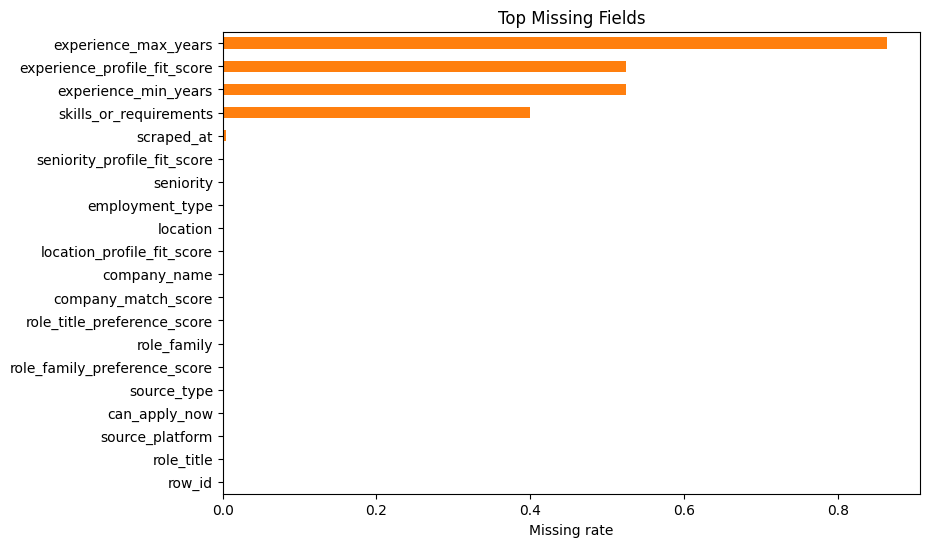

In [5]:
missing = df_raw.replace(r"^\s*$", np.nan, regex=True).isna().mean().sort_values(ascending=False)
missing_table = missing.rename("missing_rate").reset_index().rename(columns={"index": "column"})
missing_table["missing_count"] = (missing_table["missing_rate"] * len(df)).round().astype(int)
display(missing_table)

ax = missing.head(20).sort_values().plot.barh(figsize=(9, 6), color="#ff7f0e")
ax.set_title("Top Missing Fields")
ax.set_xlabel("Missing rate")
plt.show()

In [6]:
required_for_model = [
    "role_title", "role_family", "seniority", "location", "work_mode", "employment_type",
    "experience_min_years", "experience_max_years", "skills_or_requirements",
    "overall_preference_score", "applied"
]
required_for_model = [c for c in required_for_model if c in df.columns]
field_quality = pd.DataFrame({
    "column": required_for_model,
    "missing_rate": [df[c].isna().mean() for c in required_for_model],
    "unique_values": [df[c].nunique(dropna=True) for c in required_for_model],
})
display(field_quality)

,column,missing_rate,unique_values
0,role_title,0.000,201
1,role_family,0.000,137
2,seniority,0.000,47
3,location,0.000,128
4,work_mode,0.000,5
5,employment_type,0.000,26
6,experience_min_years,0.524,9
7,experience_max_years,0.864,7
8,skills_or_requirements,0.400,147
9,overall_preference_score,0.000,6


## 4. Source and Segment Coverage

This section checks whether the labeled set is dominated by a few sources, role families, locations, or companies. Dominance is not automatically bad, but it should be intentional.

In [7]:
def distribution_table(col, label_col="applied_binary", top_n=20):
    clean_col = f"{col}_clean" if f"{col}_clean" in df.columns else col
    out = df.groupby(clean_col, dropna=False).agg(
        rows=(clean_col, "size"),
        applied_rate=(label_col, "mean"),
        avg_overall_score=("overall_preference_score", "mean") if "overall_preference_score" in df.columns else (label_col, "mean"),
    ).reset_index().sort_values("rows", ascending=False)
    out["share"] = out["rows"] / len(df)
    return out.head(top_n)

for col in ["source_platform", "role_family", "seniority", "work_mode", "employment_type", "location"]:
    if col in df.columns:
        print(f"\n--- {col} ---")
        display(distribution_table(col))


--- source_platform ---


,source_platform_clean,rows,applied_rate,avg_overall_score,share
1,lever,100,0.09,2.800000,0.400
3,wellfound,68,NaN,3.970588,0.272
0,greenhouse,50,0.30,1.880000,0.200
4,workable,18,NaN,1.833333,0.072
2,remotive,14,NaN,1.571429,0.056



--- role_family ---


,role_family_clean,rows,applied_rate,avg_overall_score,share
91,fullstack,24,0.066667,2.458333,0.096
30,backend,20,0.222222,3.550000,0.080
74,frontend,10,0.200000,3.600000,0.040
9,ai engineering,9,0.000000,2.111111,0.036
93,fullstack / ai,7,0.000000,3.142857,0.028
128,generative ai / agentic ai,5,0.000000,1.600000,0.020
12,ai/ml,5,0.000000,3.000000,0.020
4,ai / generative ai,5,0.200000,2.000000,0.020
49,backend / fullstack,4,0.666667,1.750000,0.016
134,software engineering,4,0.000000,2.750000,0.016



--- seniority ---


,seniority_clean,rows,applied_rate,avg_overall_score,share
32,senior,56,0.062500,1.875000,0.224
37,unspecified,33,0.000000,2.636364,0.132
23,mid / 3+ years,18,NaN,3.666667,0.072
7,early-mid,13,0.000000,4.076923,0.052
5,early career,13,0.000000,4.615385,0.052
22,mid,11,0.363636,2.090909,0.044
16,internship / entry,10,NaN,4.800000,0.040
40,unspecified / likely mid,9,0.000000,2.444444,0.036
21,lead,8,0.000000,1.000000,0.032
36,staff,7,0.000000,1.000000,0.028


... (2 outputs left out)


--- employment_type ---


,employment_type_clean,rows,applied_rate,avg_overall_score,share
7,full-time,137,0.083333,3.014599,0.548
16,full_time,48,0.291667,1.812500,0.192
5,full time,24,0.083333,3.083333,0.096
1,contract,5,0.000000,1.600000,0.020
23,remote,5,0.000000,2.800000,0.020
19,internship/full-time listing,4,NaN,4.750000,0.016
6,full time - remote,3,0.666667,4.666667,0.012
3,employee india,3,0.000000,3.333333,0.012
17,intern,3,0.000000,3.333333,0.012
9,full-time [remote],2,0.000000,2.500000,0.008



--- location ---


,location_clean,rows,applied_rate,avg_overall_score,share
43,in office • bengaluru,20,NaN,4.000000,0.080
54,india,11,0.000000,2.545455,0.044
42,in office • bangalore urban,8,NaN,4.375000,0.032
101,remote only • india,8,NaN,4.250000,0.032
122,united states,7,0.000000,2.000000,0.028
91,remote,7,0.000000,3.714286,0.028
100,remote only • everywhere,7,NaN,4.285714,0.028
94,remote - india,6,0.166667,3.000000,0.024
104,remote • india,6,NaN,3.000000,0.024
110,remote • united states,4,NaN,1.250000,0.016


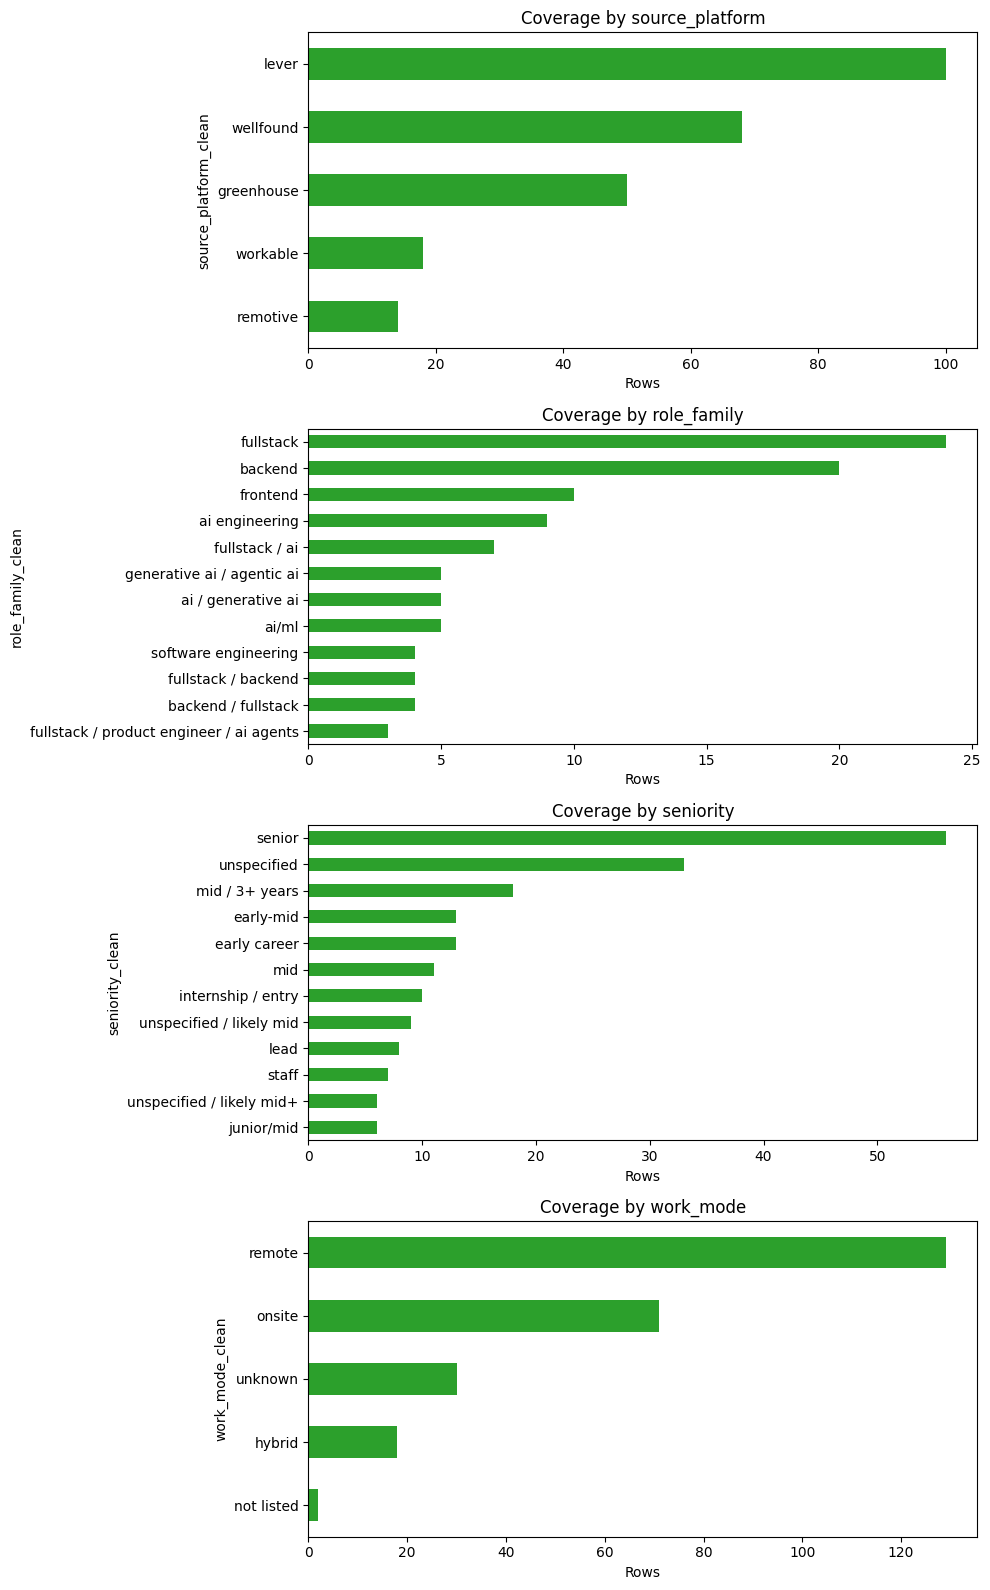

In [8]:
plot_cols = [c for c in ["source_platform_clean", "role_family_clean", "seniority_clean", "work_mode_clean"] if c in df.columns]
fig, axes = plt.subplots(len(plot_cols), 1, figsize=(10, 4 * len(plot_cols)))
if len(plot_cols) == 1:
    axes = [axes]
for ax, col in zip(axes, plot_cols):
    counts = df[col].value_counts().head(12).sort_values()
    counts.plot.barh(ax=ax, color="#2ca02c")
    ax.set_title(f"Coverage by {col.replace('_clean', '')}")
    ax.set_xlabel("Rows")
plt.tight_layout()
plt.show()

## 5. Company Concentration and Duplicate Risk

If several rows come from the same company or highly similar postings, a model can overfit company-specific wording. For validation, near-duplicate jobs and repeated companies should be kept together where practical.

In [9]:
if "company_name_clean" in df.columns:
    company_dist = distribution_table("company_name", top_n=30)
    display(company_dist)
    top_company_share = company_dist["share"].head(5).sum()
    print(f"Top 5 company share: {top_company_share:.1%}")

dup_checks = []
for col in ["apply_url", "role_title", "skills_or_requirements"]:
    if col in df.columns:
        dup_checks.append({
            "field": col,
            "duplicate_rows": int(df[col].duplicated(keep=False).sum()),
            "duplicate_rate": df[col].duplicated(keep=False).mean(),
        })
display(pd.DataFrame(dup_checks))

,company_name_clean,rows,applied_rate,avg_overall_score,share
108,mistral ai,8,0.125000,2.250000,0.032
113,netomi,6,0.333333,4.166667,0.024
152,scott logic,4,0.000000,2.000000,0.016
74,highlevel,3,0.000000,3.333333,0.012
20,binance,3,0.333333,2.666667,0.012
62,foxo,3,NaN,4.666667,0.012
181,whoop,3,0.333333,3.000000,0.012
95,lawnstarter,3,NaN,1.000000,0.012
130,patronus,3,NaN,4.666667,0.012
156,simplismart,3,NaN,3.000000,0.012


Top 5 company share: 9.6%


,field,duplicate_rows,duplicate_rate
0,apply_url,72,0.288
1,role_title,67,0.268
2,skills_or_requirements,106,0.424


## 6. Score Distribution and Label Alignment

The preference score columns are human annotations. We need to know whether they are informative, too compressed, or inconsistent with the final `applied` label.

,count,mean,std,min,25%,50%,75%,max
company_match_score,250.0,3.968000,0.835325,2.0,3.0,4.0,5.00,5.0
role_title_preference_score,250.0,3.780000,1.535262,0.0,2.0,5.0,5.00,5.0
role_family_preference_score,250.0,4.436000,0.925923,1.0,4.0,5.0,5.00,6.0
seniority_profile_fit_score,250.0,3.160000,1.469366,0.0,2.0,3.0,4.00,5.0
location_profile_fit_score,250.0,3.008000,1.785691,0.0,1.0,4.0,4.75,5.0
work_mode_fit_score,250.0,4.628000,0.683729,3.0,4.0,5.0,5.00,6.0
experience_profile_fit_score,119.0,2.445378,1.871723,0.0,1.0,2.0,4.50,5.0
skills_profile_fit_score,250.0,4.148000,1.104071,1.0,4.0,4.0,5.00,6.0
salary_profile_fit_score,250.0,5.256000,0.704592,2.0,5.0,5.0,5.00,8.0
overall_preference_score,250.0,2.796000,1.431987,0.0,2.0,3.0,4.00,5.0


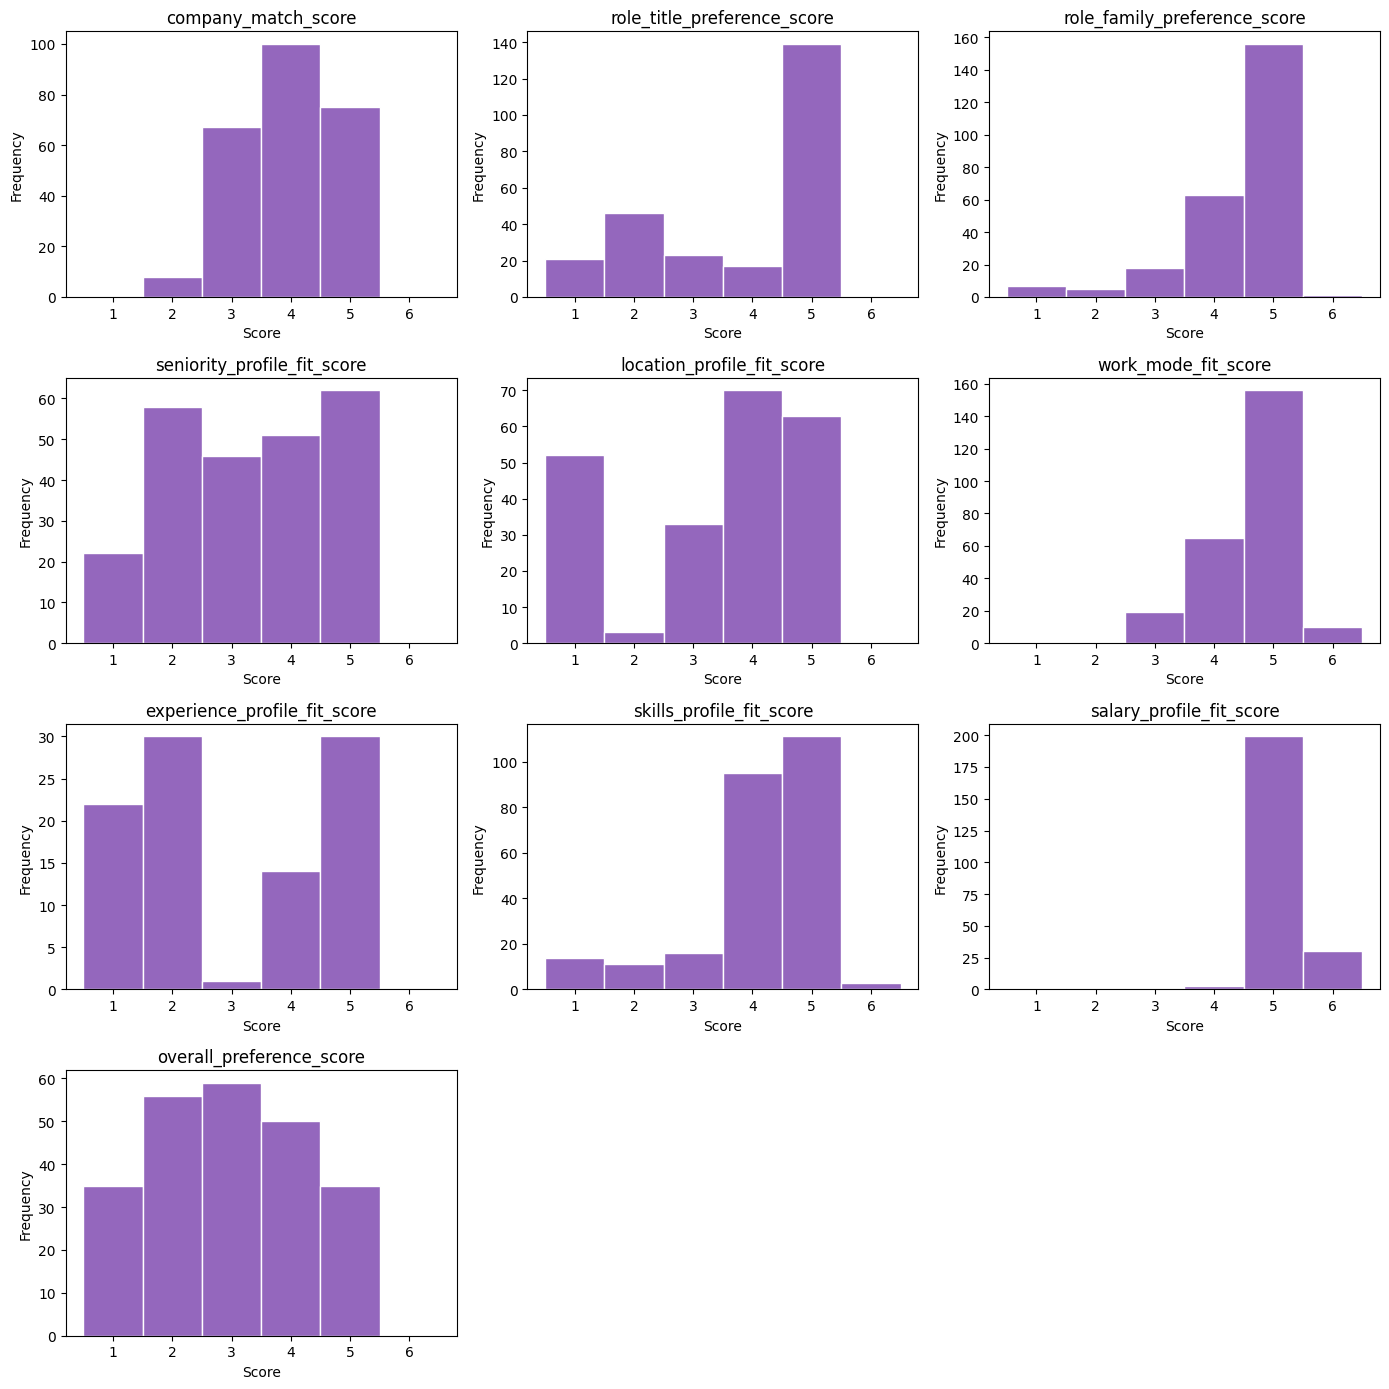

In [10]:
score_cols = [c for c in df.columns if c.endswith("_score")]
score_summary = df[score_cols].describe().T if score_cols else pd.DataFrame()
display(score_summary)

if score_cols:
    ncols = 3
    nrows = math.ceil(len(score_cols) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(14, 3.5 * nrows))
    axes = np.array(axes).reshape(-1)
    for ax, col in zip(axes, score_cols):
        df[col].dropna().plot.hist(ax=ax, bins=np.arange(0.5, 6.6, 1), color="#9467bd", edgecolor="white")
        ax.set_title(col)
        ax.set_xlabel("Score")
    for ax in axes[len(score_cols):]:
        ax.axis("off")
    plt.tight_layout()
    plt.show()

,score_column,corr_with_applied,mean_if_applied_yes,mean_if_applied_no,mean_gap_yes_minus_no
6,experience_profile_fit_score,0.524468,3.066667,0.942857,2.123810
9,overall_preference_score,0.501244,4.083333,2.190476,1.892857
3,seniority_profile_fit_score,0.291647,4.166667,2.944444,1.222222
4,location_profile_fit_score,0.206676,3.625000,2.555556,1.069444
1,role_title_preference_score,0.197883,4.458333,3.658730,0.799603
7,skills_profile_fit_score,0.182696,4.500000,3.904762,0.595238
2,role_family_preference_score,0.112641,4.625000,4.357143,0.267857
0,company_match_score,0.103012,4.458333,4.269841,0.188492
8,salary_profile_fit_score,0.006050,5.291667,5.277778,0.013889
5,work_mode_fit_score,-0.019048,4.666667,4.706349,-0.039683


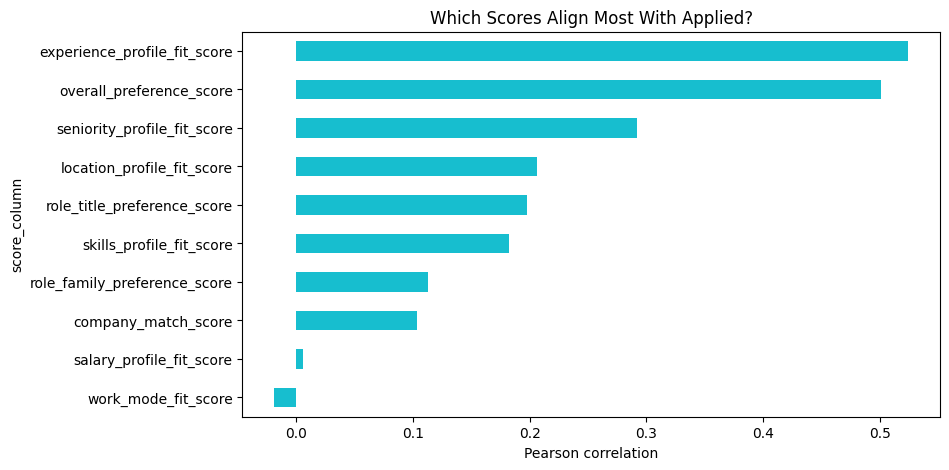

In [11]:
if score_cols and df["applied_binary"].notna().any():
    alignment = []
    for col in score_cols:
        valid = df[[col, "applied_binary"]].dropna()
        corr = valid[col].corr(valid["applied_binary"]) if len(valid) > 2 else np.nan
        mean_yes = valid.loc[valid["applied_binary"] == 1, col].mean()
        mean_no = valid.loc[valid["applied_binary"] == 0, col].mean()
        alignment.append({
            "score_column": col,
            "corr_with_applied": corr,
            "mean_if_applied_yes": mean_yes,
            "mean_if_applied_no": mean_no,
            "mean_gap_yes_minus_no": mean_yes - mean_no,
        })
    alignment = pd.DataFrame(alignment).sort_values("corr_with_applied", ascending=False)
    display(alignment)

    ax = alignment.set_index("score_column")["corr_with_applied"].sort_values().plot.barh(figsize=(9, 5), color="#17becf")
    ax.set_title("Which Scores Align Most With Applied?")
    ax.set_xlabel("Pearson correlation")
    plt.show()

## 7. Cross-Tab Bias Checks

These tables show whether some categories are almost always accepted or rejected. Extreme rates in tiny groups should not be overinterpreted; they are mainly signals for additional annotation.

In [12]:
def bias_table(group_col, min_rows=3):
    clean_col = f"{group_col}_clean" if f"{group_col}_clean" in df.columns else group_col
    out = df.groupby(clean_col).agg(
        rows=(clean_col, "size"),
        applied_rate=("applied_binary", "mean"),
        avg_overall_score=("overall_preference_score", "mean"),
        avg_role_score=("role_title_preference_score", "mean") if "role_title_preference_score" in df.columns else ("applied_binary", "mean"),
        avg_skills_score=("skills_profile_fit_score", "mean") if "skills_profile_fit_score" in df.columns else ("applied_binary", "mean"),
    ).reset_index()
    out = out[out["rows"] >= min_rows].sort_values(["applied_rate", "rows"], ascending=[False, False])
    return out

for col in ["role_family", "seniority", "work_mode", "employment_type", "source_platform"]:
    if f"{col}_clean" in df.columns:
        print(f"\n--- Applied rate by {col} ---")
        display(bias_table(col, min_rows=3))


--- Applied rate by role_family ---


,role_family_clean,rows,applied_rate,avg_overall_score,avg_role_score,avg_skills_score
35,backend / ai platform,3,1.000000,3.666667,5.000000,4.666667
49,backend / fullstack,4,0.666667,1.750000,3.000000,4.500000
110,fullstack / backend,4,0.333333,3.250000,3.250000,5.000000
30,backend,20,0.222222,3.550000,4.450000,3.850000
74,frontend,10,0.200000,3.600000,4.800000,4.900000
4,ai / generative ai,5,0.200000,2.000000,3.000000,3.200000
91,fullstack,24,0.066667,2.458333,4.041667,4.791667
9,ai engineering,9,0.000000,2.111111,4.222222,4.000000
93,fullstack / ai,7,0.000000,3.142857,4.142857,5.000000
12,ai/ml,5,0.000000,3.000000,3.800000,3.600000



--- Applied rate by seniority ---


,seniority_clean,rows,applied_rate,avg_overall_score,avg_role_score,avg_skills_score
10,entry_level,4,1.000000,4.500000,5.000000,4.750000
8,entry / sde i,4,0.750000,4.500000,4.750000,4.750000
19,junior/mid,6,0.500000,3.833333,4.500000,4.166667
22,mid,11,0.363636,2.090909,3.454545,3.363636
24,mid/senior,3,0.333333,1.000000,3.333333,3.333333
32,senior,56,0.062500,1.875000,2.196429,4.196429
37,unspecified,33,0.000000,2.636364,4.545455,4.000000
5,early career,13,0.000000,4.615385,4.923077,4.538462
7,early-mid,13,0.000000,4.076923,4.846154,4.384615
40,unspecified / likely mid,9,0.000000,2.444444,4.888889,4.333333



--- Applied rate by work_mode ---


,work_mode_clean,rows,applied_rate,avg_overall_score,avg_role_score,avg_skills_score
4,unknown,30,0.300000,1.700000,3.133333,3.933333
2,onsite,71,0.208333,3.591549,4.478873,4.154930
0,hybrid,18,0.111111,2.555556,4.055556,3.944444
3,remote,129,0.105263,2.627907,3.488372,4.217054



--- Applied rate by employment_type ---


,employment_type_clean,rows,applied_rate,avg_overall_score,avg_role_score,avg_skills_score
6,full time - remote,3,0.666667,4.666667,4.666667,4.666667
16,full_time,48,0.291667,1.812500,3.062500,3.604167
7,full-time,137,0.083333,3.014599,3.941606,4.255474
5,full time,24,0.083333,3.083333,3.916667,4.541667
1,contract,5,0.000000,1.600000,3.000000,4.200000
23,remote,5,0.000000,2.800000,4.600000,4.800000
3,employee india,3,0.000000,3.333333,3.000000,5.000000
17,intern,3,0.000000,3.333333,5.000000,4.000000
19,internship/full-time listing,4,NaN,4.750000,5.000000,4.500000



--- Applied rate by source_platform ---


,source_platform_clean,rows,applied_rate,avg_overall_score,avg_role_score,avg_skills_score
0,greenhouse,50,0.30,1.880000,3.140000,3.580000
1,lever,100,0.09,2.800000,4.110000,4.210000
3,wellfound,68,NaN,3.970588,4.455882,4.558824
4,workable,18,NaN,1.833333,2.777778,4.166667
2,remotive,14,NaN,1.571429,1.714286,3.714286


## 8. Text and Skill Signal Audit

This is a lightweight check of the `skills_or_requirements` field. It helps identify whether the dataset is dominated by one technical cluster such as backend, cloud, data, or frontend.

,skill,rows,applied_rate
63,backend,24,0.208333
164,fullstack,22,0.045455
290,product engineering,21,0.142857
13,ai,15,0.200000
303,react,11,0.181818
331,software engineering,10,0.500000
300,python,10,0.300000
47,apis,10,0.200000
158,frontend,9,0.333333
346,typescript,9,0.111111


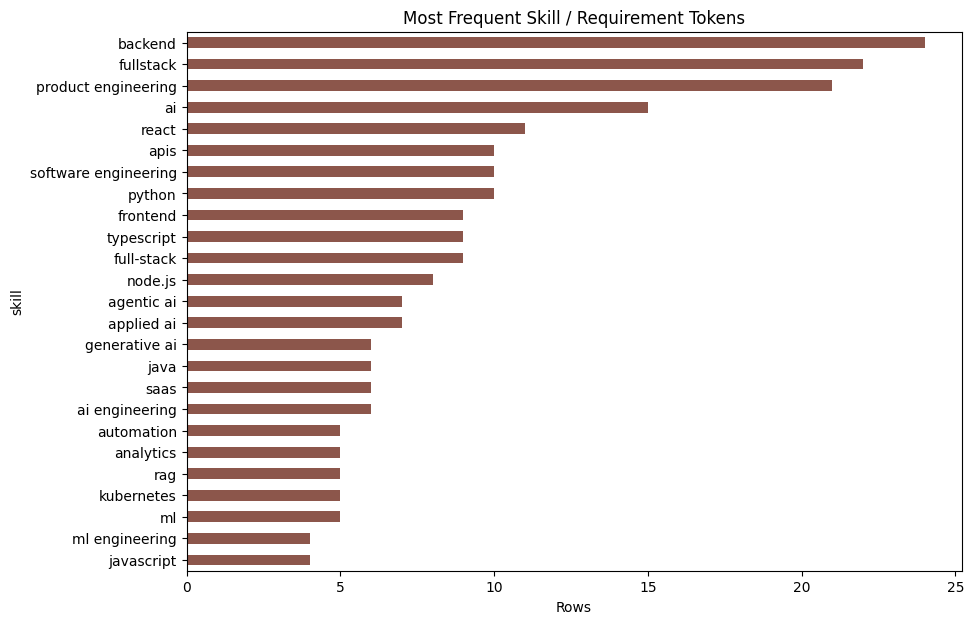

In [13]:
STOPWORDS = {
    "and", "or", "the", "a", "an", "with", "for", "to", "of", "in", "on", "as", "is", "are", "be", "likely",
    "engineering", "engineer", "software", "product", "team", "role", "experience", "knowledge", "good", "strong"
}

def tokenize_skills(text):
    if pd.isna(text):
        return []
    parts = re.split(r"[;,/|\n]+|\band\b", str(text), flags=re.IGNORECASE)
    cleaned = []
    for part in parts:
        token = re.sub(r"[^A-Za-z0-9+#.\- ]+", " ", part).strip().lower()
        token = re.sub(r"\s+", " ", token)
        if token and token not in STOPWORDS and len(token) > 1:
            cleaned.append(token)
    return cleaned

if "skills_or_requirements" in df.columns:
    skill_rows = []
    for idx, text in df["skills_or_requirements"].items():
        for token in tokenize_skills(text):
            skill_rows.append({"row_id": idx, "skill": token, "applied_binary": df.loc[idx, "applied_binary"]})
    skills = pd.DataFrame(skill_rows)
    if not skills.empty:
        skill_summary = skills.groupby("skill").agg(
            rows=("row_id", "nunique"),
            applied_rate=("applied_binary", "mean"),
        ).reset_index().sort_values("rows", ascending=False)
        display(skill_summary.head(40))
        skill_summary.head(25).sort_values("rows").plot.barh(x="skill", y="rows", figsize=(10, 7), legend=False, color="#8c564b")
        plt.title("Most Frequent Skill / Requirement Tokens")
        plt.xlabel("Rows")
        plt.show()

## 9. Sparse and Overrepresented Segment Flags

For the next annotation batch, we want fewer duplicates from saturated segments and more examples from underrepresented but strategically important segments.

In [14]:
segment_cols = [c for c in ["source_platform_clean", "role_family_clean", "seniority_clean", "work_mode_clean", "employment_type_clean"] if c in df.columns]
segment_flags = []
for col in segment_cols:
    dist = df[col].value_counts(dropna=False)
    for value, count in dist.items():
        share = count / len(df)
        if count < 5:
            flag = "too_few_examples"
        elif share > 0.30:
            flag = "dominant_segment"
        else:
            flag = "ok"
        if flag != "ok":
            segment_flags.append({"segment": col.replace("_clean", ""), "value": value, "rows": count, "share": share, "flag": flag})

segment_flags = pd.DataFrame(segment_flags).sort_values(["flag", "share"], ascending=[True, False]) if segment_flags else pd.DataFrame()
display(segment_flags)

,segment,value,rows,share,flag
162,employment_type,full-time,137,0.548,dominant_segment
160,work_mode,remote,129,0.516,dominant_segment
0,source_platform,lever,100,0.400,dominant_segment
1,role_family,fullstack / backend,4,0.016,too_few_examples
2,role_family,software engineering,4,0.016,too_few_examples
...,...,...,...,...,...
177,employment_type,full-time onsite or remote,1,0.004,too_few_examples
178,employment_type,full-time: remote,1,0.004,too_few_examples
179,employment_type,full-time/intern,1,0.004,too_few_examples
180,employment_type,part-time,1,0.004,too_few_examples


## 10. Suggested Sampling Weights

This creates lightweight inverse-frequency weights for evaluation or model training experiments. These are not final production weights, but they are useful for testing whether a model is overusing dominant categories.

In [15]:
def inverse_frequency_weight(series, cap=5.0):
    counts = series.value_counts(dropna=False)
    weights = series.map(lambda x: len(series) / (len(counts) * counts[x]))
    return weights.clip(upper=cap)

weight_cols = [c for c in ["applied_clean", "role_family_clean", "seniority_clean", "source_platform_clean"] if c in df.columns]
weights = pd.DataFrame(index=df.index)
for col in weight_cols:
    weights[f"w_{col.replace('_clean', '')}"] = inverse_frequency_weight(df[col])

if not weights.empty:
    weights["suggested_sample_weight"] = weights.mean(axis=1)
    display(weights.describe().T)
    df_audit = pd.concat([df[["row_id", "applied", "role_family", "seniority", "source_platform"]].reset_index(drop=True), weights.reset_index(drop=True)], axis=1)
    display(df_audit.sort_values("suggested_sample_weight", ascending=False).head(15))

,count,mean,std,min,25%,50%,75%,max
w_applied,250.0,1.000000,0.811343,0.661376,0.661376,0.661376,0.833333,3.472222
w_role_family,250.0,1.000000,0.736429,0.076034,0.217240,0.912409,1.824818,1.824818
w_seniority,250.0,0.942857,1.244747,0.106293,0.180375,0.457875,0.992063,5.000000
w_source_platform,250.0,1.000000,0.848398,0.500000,0.500000,0.735294,1.000000,3.571429
suggested_sample_weight,250.0,0.985714,0.468015,0.335926,0.655477,0.891962,1.242580,2.699260


,row_id,applied,role_family,seniority,source_platform,w_applied,w_role_family,w_seniority,w_source_platform,suggested_sample_weight
57,58,yes,Backend / AI-LLM / Early Career,Early Career / Student-friendly,Lever,3.472222,1.824818,5.000000,0.500000,2.699260
58,59,yes,Fullstack / AI AdTech,New grad / Early-career,Lever,3.472222,1.824818,5.000000,0.500000,2.699260
55,56,yes,AI / Software Engineering,Unspecified / likely early-mid,Lever,3.472222,0.912409,5.000000,0.500000,2.471158
220,221,Active listing / Apply visible or direct apply page found,AI Engineering,Principal / Architect,Remotive,0.833333,0.202758,5.000000,3.571429,2.401880
56,57,yes,Backend / AI Platform,New Grad / 0-2 years,Lever,3.472222,0.608273,5.000000,0.500000,2.395124
53,54,yes,AI/ML / Software Engineering,Junior / Entry level,Lever,3.472222,1.824818,2.976190,0.500000,2.193308
49,50,yes,Backend / Database Systems,mid/senior,Greenhouse,3.472222,1.824818,1.984127,1.000000,2.070292
119,120,no,Fullstack / Healthcare AI,Founding / likely mid+,Lever,0.661376,1.824818,5.000000,0.500000,1.996548
118,119,no,Fullstack / AI-powered HRTech,3+ years,Lever,0.661376,1.824818,5.000000,0.500000,1.996548
116,117,no,Data Science,Data Scientist II,Lever,0.661376,1.824818,5.000000,0.500000,1.996548


## 11. Semi-Supervised Learning Readiness Checklist

The first 250 rows are best treated as a seed annotation set. Before pseudo-labeling larger unlabeled batches, use the checks below to decide whether the seed set is robust enough.

In [16]:
checks = []

pos_rate = df["applied_binary"].mean() if df["applied_binary"].notna().any() else np.nan
checks.append({
    "area": "target_balance",
    "status": "pass" if 0.25 <= pos_rate <= 0.75 else "review",
    "detail": f"positive_rate={pos_rate:.1%}" if pd.notna(pos_rate) else "missing binary labels",
})

for col in ["role_family_clean", "seniority_clean", "source_platform_clean"]:
    if col in df.columns:
        max_share = df[col].value_counts(normalize=True).iloc[0]
        checks.append({
            "area": f"{col.replace('_clean', '')}_concentration",
            "status": "pass" if max_share <= 0.45 else "review",
            "detail": f"largest_segment_share={max_share:.1%}",
        })

critical_missing = missing[[c for c in ["role_title", "skills_or_requirements", "overall_preference_score", "applied"] if c in missing.index]].max()
checks.append({
    "area": "critical_missingness",
    "status": "pass" if critical_missing <= 0.05 else "review",
    "detail": f"max_critical_missing={critical_missing:.1%}",
})

if "apply_url" in df.columns:
    dup_url_rate = df["apply_url"].duplicated(keep=False).mean()
    checks.append({
        "area": "duplicate_apply_urls",
        "status": "pass" if dup_url_rate <= 0.05 else "review",
        "detail": f"duplicate_url_rate={dup_url_rate:.1%}",
    })

readiness = pd.DataFrame(checks)
display(readiness)

,area,status,detail
0,target_balance,review,positive_rate=16.0%
1,role_family_concentration,pass,largest_segment_share=9.6%
2,seniority_concentration,pass,largest_segment_share=22.4%
3,source_platform_concentration,pass,largest_segment_share=40.0%
4,critical_missingness,review,max_critical_missing=40.0%
5,duplicate_apply_urls,review,duplicate_url_rate=28.8%


## 12. Practical Derivations for the Next Step

Use the printed recommendations as project decisions before training:

1. **Validation split:** use stratified splits by `applied`, and consider grouping by company/apply URL to reduce leakage.
2. **Metrics:** avoid accuracy as the primary metric. Track precision, recall, F1, ROC-AUC, PR-AUC, and calibration.
3. **Sampling:** prioritize additional annotations for sparse role families, sparse seniority bands, and underrepresented sources.
4. **Pseudo-labeling:** only accept pseudo-labels at high model confidence and keep a human review queue for uncertain rows.
5. **Features:** start with interpretable tabular + text features before deep learning. Use score columns as labels/signals carefully because they are human-created annotations, not raw job facts.
6. **Leakage control:** do not train on `preference_reason` if it was written after deciding `applied`; it can leak the target decision.

In [17]:
recommendations = []

if pd.notna(pos_rate) and (pos_rate < 0.25 or pos_rate > 0.75):
    recommendations.append("Collect more labels from the minority applied class before relying on supervised metrics.")
else:
    recommendations.append("The target label balance is usable for a first baseline, but validation must remain stratified.")

if not segment_flags.empty:
    sparse = segment_flags[segment_flags["flag"] == "too_few_examples"]
    dominant = segment_flags[segment_flags["flag"] == "dominant_segment"]
    if not sparse.empty:
        recommendations.append(f"Add annotations for sparse segments: {', '.join((sparse['segment'] + '=' + sparse['value'].astype(str)).head(8))}.")
    if not dominant.empty:
        recommendations.append(f"Avoid over-sampling dominant segments next: {', '.join((dominant['segment'] + '=' + dominant['value'].astype(str)).head(5))}.")

if "preference_reason" in df.columns:
    recommendations.append("Treat preference_reason as an explanation artifact, not a first-pass training feature, unless generated before the final applied label.")

if "apply_url" in df.columns and df["apply_url"].duplicated(keep=False).any():
    recommendations.append("Deduplicate or group duplicate apply URLs before train/test splitting.")

print("Recommended next actions:")
for idx, rec in enumerate(recommendations, start=1):
    print(f"{idx}. {rec}")

Recommended next actions:
1. Collect more labels from the minority applied class before relying on supervised metrics.
2. Add annotations for sparse segments: role_family=fullstack / backend, role_family=software engineering, role_family=backend / fullstack, seniority=senior-heavy, seniority=sde ii, seniority=graduate, seniority=entry_level, seniority=entry / sde i.
3. Avoid over-sampling dominant segments next: employment_type=full-time, work_mode=remote, source_platform=lever.
4. Treat preference_reason as an explanation artifact, not a first-pass training feature, unless generated before the final applied label.
5. Deduplicate or group duplicate apply URLs before train/test splitting.


## 13. Student Deep Dive: How To Read This EDA And Bias Audit

Important context: this notebook was run on an earlier 250-row annotation snapshot. Later in the project, the `applied` column was fixed to clean binary values and the master dataset was expanded to 331 rows. So use this notebook mainly to learn the EDA thinking process. For final model conclusions, rely on the current `data/jedi_master_prepared.csv` and the model notebooks.

### What EDA is for

EDA means exploratory data analysis. The goal is not to train a model yet. The goal is to ask: is this dataset trustworthy enough to train on, and what problems should we handle before modeling?

For JEDI, the important questions are:

- Is the target label `applied` clean?
- Are yes/no classes balanced enough?
- Are some segments overrepresented, such as remote jobs or one source platform?
- Are important fields missing too often?
- Are duplicate or near-duplicate jobs likely to leak across train/test split?
- Do your manual scores align with the final applied decision?
- Which categories need more manual examples before semi-supervised learning?

### How to interpret each EDA section

Section 1 loads the data and standardizes labels for audit. This is where you first check whether the file loaded correctly, whether row count matches expectation, and whether columns have the expected types.

Section 2 checks target class balance. In the old run, `applied` was not clean binary: it contained `no`, `yes`, and `active listing / apply visible...`. That was a serious issue because a classifier needs the target to mean one thing. You later fixed this, which was the right decision.

Section 3 checks missingness. Missingness matters because a model can only learn from fields that exist consistently. In the old audit, `skills_or_requirements` was missing for 40% of rows and `experience_min_years` was missing for 52.4%. That is why we later filled missing skills using rule-based descriptions and decided to use `experience_min_years` but ignore `experience_max_years`.

Section 4 checks source and segment coverage. This tells you whether your dataset is mostly one type of job. In the old audit, remote jobs and some platforms were heavily represented. If one source dominates, the model can learn source style instead of job preference. That is why source columns were later dropped from training.

Section 5 checks company concentration and duplicates. Duplicate jobs are dangerous because a similar job can appear in train and test, making metrics look better than real deployment. The old audit found duplicate apply URL risk, which is why later modeling notes mention grouped splits by `near_duplicate_key`.

Section 6 checks score distributions. This tells you whether your manual score columns have useful variation. A score with almost no variation cannot teach much. A score with strong correlation to `applied` may be useful later for preference-score regression, but should not be used as a feature for the first binary classifier.

Section 7 checks cross-tabs like applied rate by role family, seniority, work mode, employment type, and source. These tables help you detect sampling bias. If a category has only 3 rows and 100% applied rate, do not conclude that category is always good. Small groups are unstable.

Section 8 checks text and skill signals. This tells you which skills appear frequently and whether they are associated with applied decisions. For JEDI this matters because title and skills are core preference signals.

Section 9 flags sparse and overrepresented segments. Sparse segments need more labels before the model can learn them. Dominant segments should not receive too many more examples unless they are genuinely important.

Section 10 creates suggested sampling weights. The idea is simple: underrepresented or important examples should receive more attention in future collection or training. This is not magic; it is a practical way to fight imbalance.

Section 11 gives a readiness checklist. A checklist is useful because semi-supervised learning can amplify mistakes. If labels are messy, duplicates leak, or important fields are missing, pseudo-labeling will spread those errors.

### How to decide actions from EDA

Do not treat every chart as an action item. Use this rule:

- If a field is important and missing often, fix/impute/standardize it before modeling.
- If a category dominates the dataset, collect less of it unless it is the real production distribution.
- If a category is important but sparse, collect more examples from it.
- If a label column has ambiguous values, stop and clean it before training.
- If duplicate risk exists, split data by duplicate group instead of row-by-row random split.
- If a score column is highly aligned with `applied`, save it for a separate regression or multi-task model, not as a direct feature in the first binary classifier.

### What changed after this EDA

The correct follow-up actions were taken later: `applied` was cleaned into binary labels, skills were filled and normalized, `source_platform` was excluded from training, employment/work mode/seniority/role family were standardized, and location helper fields such as `is_bengaluru`, `is_gurgaon_ncr`, and `is_india` were added.

The remaining caution is duplicate leakage and dataset size. The current model notebooks use a random split for the first baseline, which is fine for learning. Before claiming final production performance, rerun validation with grouped splits and more manually labeled borderline jobs.